In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
block_size = 3

def build_dataset(words):  
    X, Y = [], []
  
    for w in words:
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [105]:
n_embd = 10
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),             generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5)
W2 = torch.randn((n_hidden, vocab_size),          generator=g) * 0.01
b2 = torch.randn(vocab_size,                       generator=g) * 0

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros(1, n_hidden)
bnstd_running = torch.ones(1, n_hidden)
bnmean_running = torch.zeros(1, n_hidden)

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad=True

12297


In [ ]:
max_steps = 200000
batch_size = 32
track_size_print = 10000
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xtr[ix]]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 # + b1
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % track_size_print == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

    # break
# print(loss.item())

      0/ 200000: 3.2983
  10000/ 200000: 2.3207
  20000/ 200000: 2.2027
  30000/ 200000: 2.3159
  40000/ 200000: 1.7513
  50000/ 200000: 1.8446
  60000/ 200000: 2.3891
  70000/ 200000: 2.1385
  80000/ 200000: 2.2844
  90000/ 200000: 2.1030
 100000/ 200000: 2.3168
 110000/ 200000: 1.9848
 120000/ 200000: 2.0873
 130000/ 200000: 2.0668
 140000/ 200000: 1.9982
 150000/ 200000: 2.1659
 160000/ 200000: 2.5112
 170000/ 200000: 1.7588
 180000/ 200000: 1.8461
 190000/ 200000: 1.9145


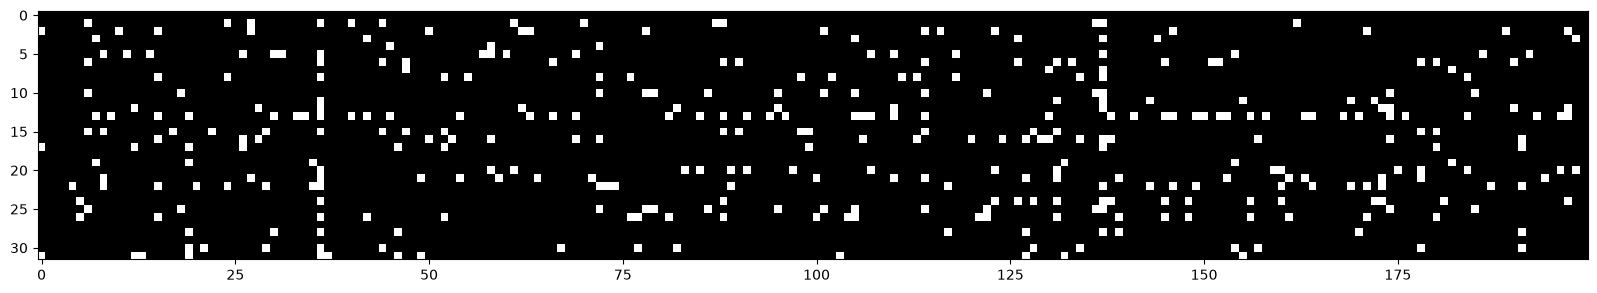

In [87]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

(array([433., 255., 182., 135., 171., 118., 115., 129.,  96.,  78.,  87.,
         79.,  59., 108.,  89.,  91., 125., 114., 113.,  74.,  86.,  84.,
        121., 125., 137., 108., 118., 100., 150., 124., 124.,  87.,  81.,
        146.,  98., 115.,  57., 102.,  64.,  78.,  91., 115., 131., 113.,
        106., 114., 144., 160., 218., 452.]),
 array([-9.99945462e-01, -9.59946558e-01, -9.19947655e-01, -8.79948752e-01,
        -8.39949849e-01, -7.99950945e-01, -7.59952042e-01, -7.19953139e-01,
        -6.79954236e-01, -6.39955332e-01, -5.99956429e-01, -5.59957526e-01,
        -5.19958622e-01, -4.79959719e-01, -4.39960816e-01, -3.99961913e-01,
        -3.59963009e-01, -3.19964106e-01, -2.79965203e-01, -2.39966300e-01,
        -1.99967396e-01, -1.59968493e-01, -1.19969590e-01, -7.99706864e-02,
        -3.99717832e-02,  2.71201134e-05,  4.00260234e-02,  8.00249267e-02,
         1.20023830e-01,  1.60022733e-01,  2.00021636e-01,  2.40020540e-01,
         2.80019443e-01,  3.20018346e-01,  3.60017

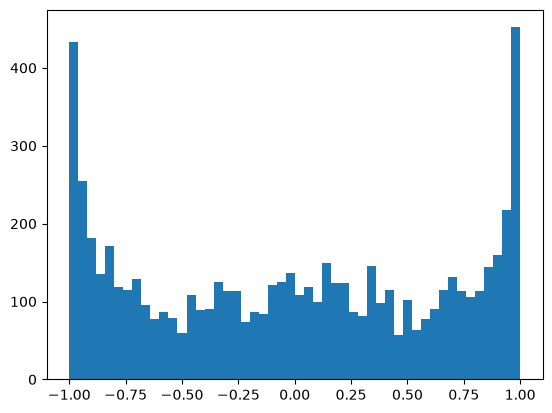

In [88]:
plt.hist(h.view(-1).tolist(), 50)

(array([  3.,   1.,   3.,   3.,   4.,  12.,  19.,  28.,  48.,  66.,  75.,
        104., 119., 204., 221., 298., 370., 344., 567., 660., 782., 567.,
        381., 362., 265., 212., 161., 134., 110.,  77.,  59.,  43.,  24.,
         26.,  17.,  11.,   5.,   4.,   6.,   1.,   1.,   0.,   1.,   0.,
          0.,   0.,   0.,   0.,   0.,   2.]),
 array([-5.25473547, -4.99272408, -4.7307127 , -4.46870131, -4.20668993,
        -3.94467854, -3.68266716, -3.42065578, -3.15864439, -2.89663301,
        -2.63462162, -2.37261024, -2.11059885, -1.84858747, -1.58657608,
        -1.3245647 , -1.06255331, -0.80054193, -0.53853054, -0.27651916,
        -0.01450777,  0.24750361,  0.509515  ,  0.77152638,  1.03353777,
         1.29554915,  1.55756054,  1.81957192,  2.08158331,  2.34359469,
         2.60560608,  2.86761746,  3.12962885,  3.39164023,  3.65365162,
         3.915663  ,  4.17767439,  4.43968577,  4.70169716,  4.96370854,
         5.22571993,  5.48773131,  5.7497427 ,  6.01175408,  6.27376547,
 

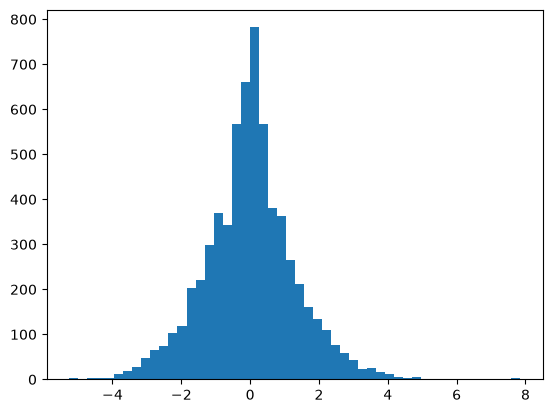

In [89]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [90]:
-torch.tensor(1/27.0).log()

tensor(3.2958)

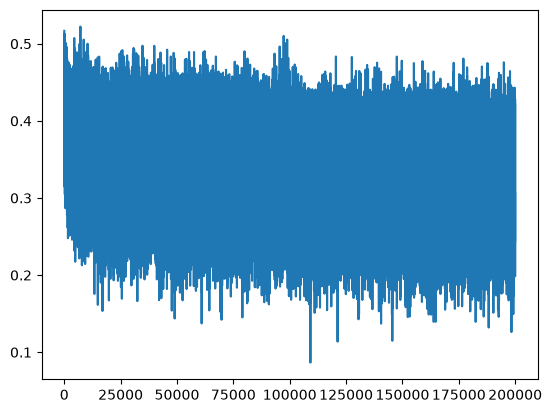

In [91]:
plt.plot(lossi)

In [94]:
with torch.no_grad():
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 # + b1

  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim=True)

In [104]:
@torch.no_grad() 
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] 
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  # hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.066415309906006
val 2.10992169380188


In [ ]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
  out = []  
  context = [0] * block_size
  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ W1 + b1)
    logits = h @ W2 + b2
    probs = F.softmax(logits, dim=1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()
    context = context[1:] + [ix]
    out.append(ix)
    if ix == 0:
      break
    
  print(''.join(itos[i] for i in out))

carlah.
amille.
khy.
mili.
tatyannah.
salee.
hube.
den.
art.
kaeli.
nellara.
chaiiv.
kaleigh.
ham.
join.
quinn.
sulin.
alianni.
watthoniearynn.
jaxen.
